# Encontro 2 — Python I: notebook, variáveis, listas, laços e funções

**Modelagem Dinâmica Espacial · LambdaGeo/UFMA**

Este é o primeiro contato com Python. Ninguém precisa saber programar: o objetivo de hoje é **ler, rodar e alterar** pequenos pedaços de código. Ao final, você terá escrito um modelo de crescimento populacional que é, sem o nome, o primeiro modelo de dinâmica de sistemas da disciplina.

Marcas usadas nos notebooks:

- 🔧 troque um número e rode de novo;
- ✏️ responda à pergunta (escreva a resposta numa célula de texto logo abaixo).

## 1. O notebook

Um notebook é uma sequência de **células**. Há dois tipos:

- **texto** (como esta), para explicar;
- **código**, que o Python executa.

Para rodar uma célula, clique nela e aperte **Shift + Enter**. O número que aparece ao lado, `[1]`, `[2]`..., mostra a ordem em que as células rodaram. Rode a célula abaixo.

In [1]:
print("Olá! Este notebook está funcionando.")

Olá! Este notebook está funcionando.


A última linha de uma célula de código é mostrada automaticamente, mesmo sem `print`:

In [2]:
2 + 3

5

## 2. Python como calculadora

As operações usuais: `+`, `-`, `*` (multiplicação), `/` (divisão), `**` (potência). O texto depois de `#` é um **comentário**: o Python ignora.

In [3]:
1_000 * 1.015      # mil habitantes, depois de um ano crescendo 1,5%

1014.9999999999999

In [4]:
1_000 * 1.015 ** 10   # depois de dez anos (o _ separa os milhares, só para facilitar a leitura)

1160.540825025149

Repare no `1014.9999999999999` da penúltima célula, em vez de `1015`. Não é erro do Python: o computador guarda os decimais em binário, e alguns, como 1,015, não têm representação exata. A diferença está na 13ª casa e quase nunca importa, mas explica por que dois programas "iguais" podem discordar no último dígito. Voltamos a isso no encontro 4.

## 3. Variáveis

Uma **variável** é um nome que guarda um valor. O sinal `=` quer dizer "guarde", não "é igual".

In [5]:
populacao = 1_000_000     # habitantes
taxa = 0.015              # crescimento por ano (1,5%)

populacao * taxa          # quantos habitantes a mais em um ano

15000.0

Depois de guardar, o nome pode ser usado em qualquer célula seguinte. E pode ser atualizado:

In [6]:
populacao = populacao + populacao * taxa   # o lado direito é calculado primeiro, depois guardado
populacao

1015000.0

🔧 Rode a célula acima mais duas vezes. O que acontece com `populacao`? Isso mostra uma regra importante do notebook: **a ordem em que você roda importa**, não a ordem em que as células aparecem na página. Para recomeçar do zero, use o menu *Kernel → Restart* (ou *Ambiente de execução → Reiniciar*, no Colab).

### Tipos de valor

Cada valor tem um **tipo**. Os que mais vamos usar:

| Tipo | Exemplo | Para quê |
|---|---|---|
| `int` (inteiro) | `2024`, `-3` | contagens, anos |
| `float` (decimal) | `0.015`, `3.14` | medidas, taxas (o separador é o **ponto**) |
| `str` (texto) | `"São Luís"` | nomes, classes |
| `bool` (lógico) | `True`, `False` | respostas sim/não |

In [7]:
municipio = "São Luís"
ano = 2024
area_km2 = 583.063          # malha municipal do IBGE, 2022
capital = True

print(type(municipio), type(ano), type(area_km2), type(capital))

<class 'str'> <class 'int'> <class 'float'> <class 'bool'>


Uma forma prática de montar frases com valores é a *f-string*: um `f` antes das aspas e os nomes entre chaves.

In [8]:
print(f"{municipio} tem {area_km2} km². Capital? {capital}")
print(f"Com duas casas decimais: {populacao:,.2f} habitantes")   # vírgula separa milhares (padrão inglês)

São Luís tem 583.063 km². Capital? True
Com duas casas decimais: 1,015,000.00 habitantes


✏️ **Pergunta 1.** Crie uma variável `densidade` com a população dividida pela área de São Luís e mostre o valor numa frase. Que unidade ela tem?

In [9]:
# sua resposta aqui


## 4. Listas

Uma **lista** guarda vários valores, em ordem, entre colchetes.

In [10]:
anos = [2020, 2021, 2022, 2023, 2024]
area_desmatada = [12.0, 15.5, 9.8, 11.2, 7.4]     # km² por ano (valores de exemplo)

print(len(anos), "anos")
print("primeiro ano:", anos[0])       # a contagem começa em 0
print("último ano:", anos[-1])        # -1 é o último
print("três primeiros:", anos[0:3])   # do índice 0 até antes do 3

5 anos
primeiro ano: 2020
último ano: 2024
três primeiros: [2020, 2021, 2022]


In [11]:
print("total:", sum(area_desmatada), "km²")
print("maior:", max(area_desmatada), "km²")

area_desmatada.append(6.1)    # acrescenta um valor no fim
anos.append(2025)
print(anos, area_desmatada)

total: 55.9 km²
maior: 15.5 km²
[2020, 2021, 2022, 2023, 2024, 2025] [12.0, 15.5, 9.8, 11.2, 7.4, 6.1]


✏️ **Pergunta 2.** Qual expressão dá a área desmatada em 2022? Por que não é `area_desmatada[2022]`?

## 5. Laços: repetir uma conta

Um laço `for` repete um bloco de código para cada valor de uma sequência. O bloco que se repete é o que está **recuado** (4 espaços) depois dos dois-pontos.

In [12]:
for ano, area in zip(anos, area_desmatada):    # zip anda pelas duas listas juntas
    print(f"{ano}: {area} km²")

2020: 12.0 km²
2021: 15.5 km²
2022: 9.8 km²
2023: 11.2 km²
2024: 7.4 km²
2025: 6.1 km²


O laço mais útil nesta disciplina é o que **simula o tempo**: a cada volta, calcula o valor do ano seguinte a partir do atual. `range(10)` produz os números 0, 1, ..., 9.

In [13]:
populacao = 1_000_000
taxa = 0.015
historico = [populacao]          # começa com o valor inicial

for ano in range(10):
    populacao = populacao + populacao * taxa
    historico.append(populacao)

print(len(historico), "valores")
print(f"depois de 10 anos: {historico[-1]:,.0f} habitantes")

11 valores
depois de 10 anos: 1,160,541 habitantes


Esse é o esqueleto de **todos** os modelos dinâmicos da disciplina: um estado (aqui, a população), uma regra que o atualiza e um laço que repete a regra passo a passo.

### Condições

`if` executa um bloco só quando uma condição é verdadeira. Junto com o laço, permite perguntar **quando** algo acontece.

In [14]:
populacao = 1_000_000
ano = 0
while populacao < 2_000_000:       # while: repete enquanto a condição for verdadeira
    populacao = populacao * (1 + taxa)
    ano = ano + 1

print(f"A população dobra em {ano} anos.")

A população dobra em 47 anos.


🔧 Troque a taxa para 0,03 (3% ao ano) e rode de novo. O tempo para dobrar cai pela metade?

## 6. Funções: dar nome a um procedimento

Quando uma conta vai ser repetida com valores diferentes, ela vira uma **função**: um bloco com nome, que recebe valores (os *parâmetros*) e devolve um resultado com `return`.

In [15]:
def crescimento(inicial, taxa, anos):
    """Devolve a lista de valores, ano a ano, de um crescimento à taxa constante."""
    valores = [inicial]
    for _ in range(anos):
        valores.append(valores[-1] * (1 + taxa))
    return valores


serie = crescimento(1_000_000, 0.015, 30)
print(f"{serie[-1]:,.0f} habitantes depois de 30 anos")

1,563,080 habitantes depois de 30 anos


## 7. Gráficos

A biblioteca `matplotlib` desenha gráficos. `import` traz uma biblioteca para o notebook; `plt` é o apelido costumeiro.

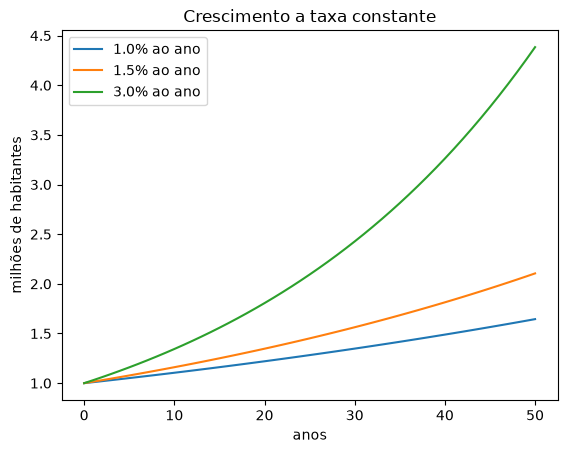

In [16]:
import matplotlib.pyplot as plt

for taxa in [0.01, 0.015, 0.03]:
    serie = crescimento(1_000_000, taxa, 50)
    plt.plot([v / 1e6 for v in serie], label=f"{taxa:.1%} ao ano")   # em milhões

plt.xlabel("anos"); plt.ylabel("milhões de habitantes"); plt.title("Crescimento a taxa constante")
plt.legend();

Crescer sempre à mesma taxa leva a valores que não param de subir. Na realidade, falta espaço, água ou emprego, e o crescimento desacelera. Um modelo clássico para isso é o **logístico**: a taxa diminui à medida que a população se aproxima de uma **capacidade** máxima.

taxa efetiva = taxa × (1 − população / capacidade)

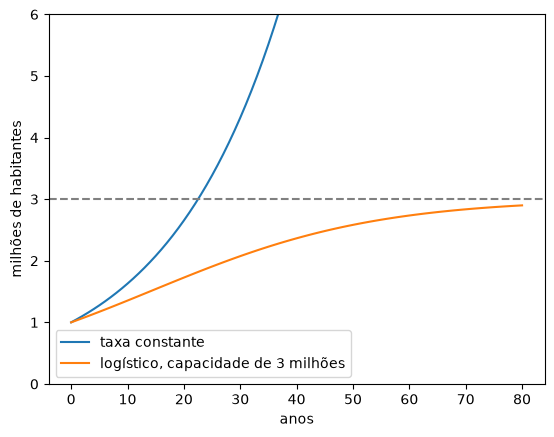

In [17]:
def logistico(inicial, taxa, capacidade, anos):
    valores = [inicial]
    for _ in range(anos):
        p = valores[-1]
        valores.append(p + p * taxa * (1 - p / capacidade))
    return valores


milhoes = lambda serie: [v / 1e6 for v in serie]
plt.plot(milhoes(crescimento(1_000_000, 0.05, 80)), label="taxa constante")
plt.plot(milhoes(logistico(1_000_000, 0.05, 3_000_000, 80)), label="logístico, capacidade de 3 milhões")
plt.axhline(3, color="gray", linestyle="--")
plt.ylim(0, 6); plt.xlabel("anos"); plt.ylabel("milhões de habitantes"); plt.legend();

✏️ **Pergunta 3.** No modelo logístico, o que acontece se a população **começar acima** da capacidade (por exemplo, 4 milhões)? Rode e explique pela fórmula.

Guarde este exemplo: no encontro 5 ele volta com outro nome, como um modelo de **estoque e fluxo**.

## 8. Ler mensagens de erro

Errar faz parte. O importante é saber **ler** o erro: a última linha diz o tipo e o motivo; as linhas acima mostram onde ele aconteceu. As células abaixo têm erros de propósito.

**Nome não definido** — a variável não existe (erro de digitação, ou a célula que a cria não foi rodada):

In [18]:
print(populaçao)

NameError: name 'populaçao' is not defined

**Tipo errado** — somar texto com número:

In [19]:
ano = "2024"
ano + 1

TypeError: can only concatenate str (not "int") to str

**Índice fora da lista** — a lista tem 6 valores, de 0 a 5:

In [20]:
area_desmatada[6]

IndexError: list index out of range

**Recuo** — o bloco do `for` precisa estar recuado:

In [21]:
for ano in anos:
print(ano)

IndentationError: expected an indented block after 'for' statement on line 1 (2079903691.py, line 2)

| Erro | Em português | O que conferir |
|---|---|---|
| `NameError` | nome não definido | digitação; se a célula que cria o nome foi rodada |
| `TypeError` | tipo errado na operação | se o valor é texto (`"2024"`) ou número (`2024`) |
| `IndexError` | índice fora do intervalo | o tamanho da lista (`len`) e que a contagem começa em 0 |
| `IndentationError` | recuo errado | os 4 espaços depois de `for`, `if`, `def` |
| `SyntaxError` | Python não entendeu a linha | parênteses, aspas e dois-pontos |

✏️ **Pergunta 4.** Corrija as quatro células com erro acima, cada uma numa célula nova.

## Para casa

1. Escreva uma função `anos_para_dobrar(taxa)` que devolva em quantos anos um valor dobra crescendo à `taxa`. Teste com 1%, 2% e 5%. A "regra do 70" diz que a resposta é cerca de 70 dividido pela taxa em porcentagem: ela funciona?
2. A cobertura florestal de um município é de 800 km² e perde 3% ao ano. Use um laço para descobrir em que ano ela fica abaixo de 400 km². Faça o gráfico.
3. No modelo logístico, faça um gráfico com capacidades de 2, 3 e 5 milhões. O que a capacidade muda: a forma da curva ou só a altura?